# Amazon Prime Movies and TV Shows – Machine Learning

## Project Overview
This project uses Machine Learning to classify Amazon Prime titles into two categories: Movies and TV Shows.

## Objectives
- Prepare and clean the dataset.
- Perform feature preprocessing.
- Train Logistic Regression and Random Forest classifiers.
- Evaluate model performance.
- Compare models and select the best-performing model.

## Best Model
Random Forest Classifier

**Test Accuracy:** 97.67%

**Macro F1-score:** 0.9527

In [14]:
# Import required libraries

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("ALL LIBRARIES IMPORTED SUCCESSFULLY!")

ALL LIBRARIES IMPORTED SUCCESSFULLY!


In [15]:
from google.colab import drive

# Connect Google Drive
drive.mount('/content/drive')

# Dataset folder
dataset_path = "/content/drive/MyDrive/Amazon_Prime_Dataset"

# Load datasets
titles = pd.read_csv(
    os.path.join(dataset_path, "titles.csv")
)

credits = pd.read_csv(
    os.path.join(dataset_path, "credits.csv")
)

print("DATASETS LOADED SUCCESSFULLY!")
print("Titles shape:", titles.shape)
print("Credits shape:", credits.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATASETS LOADED SUCCESSFULLY!
Titles shape: (9871, 15)
Credits shape: (124235, 5)


## 1. Data Cleaning and Preparation

In [16]:
# Create a separate ML dataset using titles data

df_ml = titles.copy()

# Remove duplicate records
df_ml = df_ml.drop_duplicates()

# Remove records with missing target values
df_ml = df_ml.dropna(subset=['type'])

# Reset index
df_ml = df_ml.reset_index(drop=True)

print("ML DATASET CREATED SUCCESSFULLY!")

print("\nDataset shape:", df_ml.shape)

print("\nContent type distribution:")
print(df_ml['type'].value_counts())

print("\nDuplicate records:", df_ml.duplicated().sum())

display(df_ml.head())

ML DATASET CREATED SUCCESSFULLY!

Dataset shape: (9868, 15)

Content type distribution:
type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64

Duplicate records: 0


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


## 2. Feature Selection and Target Variable

In [17]:
# Separate input features and target variable

X = df_ml.drop(
    columns=['type', 'id', 'title', 'imdb_id', 'seasons']
)

y = df_ml['type']

# Handle missing text and categorical values
text_columns = [
    'description',
    'genres',
    'production_countries'
]

for col in text_columns:
    X[col] = X[col].fillna('')

X['age_certification'] = X['age_certification'].fillna('Unknown')

print("FEATURES AND TARGET CREATED SUCCESSFULLY!")

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values:")
print(X.isnull().sum())

FEATURES AND TARGET CREATED SUCCESSFULLY!

Feature shape: (9868, 10)
Target shape: (9868,)

Target distribution:
type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64

Missing values:
description                0
release_year               0
age_certification          0
runtime                    0
genres                     0
production_countries       0
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2080
dtype: int64


## 3. Splitting Data into Training and Testing Sets

In [18]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("DATASET SPLIT SUCCESSFULLY!")

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

DATASET SPLIT SUCCESSFULLY!

Training features: (7894, 10)
Testing features: (1974, 10)

Training target distribution:
type
MOVIE    6808
SHOW     1086
Name: count, dtype: int64

Testing target distribution:
type
MOVIE    1703
SHOW      271
Name: count, dtype: int64


## 4. Data Preprocessing

In [19]:
# Define feature columns

numeric_features = [
    'release_year',
    'runtime',
    'imdb_score',
    'imdb_votes',
    'tmdb_popularity',
    'tmdb_score'
]

categorical_features = ['age_certification']

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),

    ('cat', categorical_transformer, categorical_features),

    ('description', TfidfVectorizer(
        max_features=200,
        stop_words='english'
    ), 'description'),

    ('genres', TfidfVectorizer(
        max_features=50
    ), 'genres'),

    ('countries', TfidfVectorizer(
        max_features=30
    ), 'production_countries')
])

print("PREPROCESSING PIPELINE CREATED SUCCESSFULLY!")

PREPROCESSING PIPELINE CREATED SUCCESSFULLY!


## 5. Applying Data Preprocessing

In [20]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("DATA PREPROCESSING COMPLETED SUCCESSFULLY!")

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

DATA PREPROCESSING COMPLETED SUCCESSFULLY!

Processed training shape: (7894, 267)
Processed testing shape: (1974, 267)


## 6. Logistic Regression Model

In [21]:
# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# Train model
lr_model.fit(X_train_processed, y_train)

# Predictions
y_pred_lr = lr_model.predict(X_test_processed)

# Evaluate
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("LOGISTIC REGRESSION TRAINED SUCCESSFULLY!")

print("\nAccuracy:", round(accuracy_lr * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION TRAINED SUCCESSFULLY!

Accuracy: 97.21 %

Classification Report:
              precision    recall  f1-score   support

       MOVIE       1.00      0.97      0.98      1703
        SHOW       0.84      0.99      0.91       271

    accuracy                           0.97      1974
   macro avg       0.92      0.98      0.95      1974
weighted avg       0.98      0.97      0.97      1974


Confusion Matrix:
[[1652   51]
 [   4  267]]


## 7. Random Forest Model

In [22]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train_processed, y_train)

# Predictions
y_pred_rf = rf_model.predict(X_test_processed)

# Evaluate
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("RANDOM FOREST TRAINED SUCCESSFULLY!")

print("\nAccuracy:", round(accuracy_rf * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST TRAINED SUCCESSFULLY!

Accuracy: 97.67 %

Classification Report:
              precision    recall  f1-score   support

       MOVIE       0.99      0.98      0.99      1703
        SHOW       0.88      0.96      0.92       271

    accuracy                           0.98      1974
   macro avg       0.94      0.97      0.95      1974
weighted avg       0.98      0.98      0.98      1974


Confusion Matrix:
[[1667   36]
 [  10  261]]


## 8. Model Performance Comparison

In [23]:
# Calculate Macro F1 scores
f1_lr = f1_score(y_test, y_pred_lr, average='macro')
f1_rf = f1_score(y_test, y_pred_rf, average='macro')

# Compare models
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy (%)': [
        accuracy_lr * 100,
        accuracy_rf * 100
    ],
    'Macro F1 Score': [f1_lr, f1_rf]
})

display(model_comparison.round(4))

# Select best model
if f1_rf > f1_lr:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print("Best Model:", best_model_name)

,Model,Accuracy (%),Macro F1 Score
0,Logistic Regression,97.2138,0.9451
1,Random Forest,97.6697,0.9527


Best Model: Random Forest


## 9. Model Evaluation Visualizations

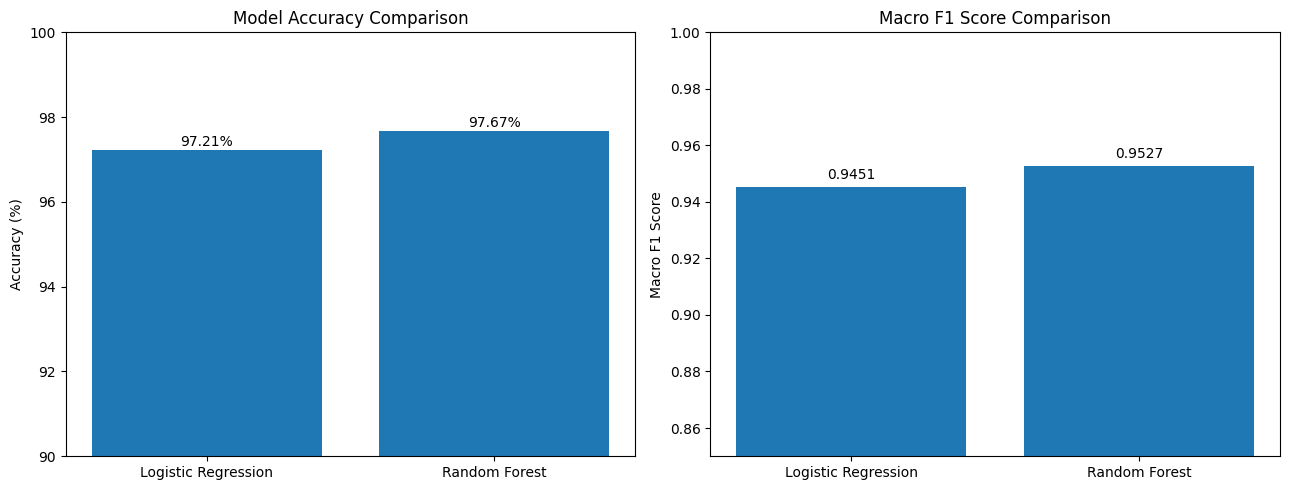

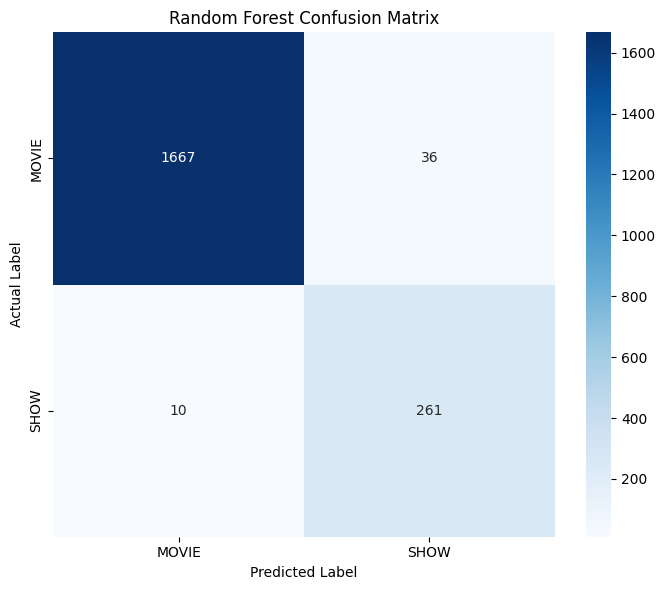

In [24]:
# Accuracy and F1 comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = ['Logistic Regression', 'Random Forest']
accuracies = [accuracy_lr * 100, accuracy_rf * 100]
f1_scores = [f1_lr, f1_rf]

axes[0].bar(models, accuracies)
axes[0].set_title('Model Accuracy Comparison')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(90, 100)

for i, value in enumerate(accuracies):
    axes[0].text(i, value + 0.1, f'{value:.2f}%', ha='center')

axes[1].bar(models, f1_scores)
axes[1].set_title('Macro F1 Score Comparison')
axes[1].set_ylabel('Macro F1 Score')
axes[1].set_ylim(0.85, 1.0)

for i, value in enumerate(f1_scores):
    axes[1].text(i, value + 0.003, f'{value:.4f}', ha='center')

plt.tight_layout()
plt.show()

# Random Forest confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['MOVIE', 'SHOW'],
    yticklabels=['MOVIE', 'SHOW']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

## 10. Saving the Best Machine Learning Model

In [25]:
# Create model folder
os.makedirs("ML_Models", exist_ok=True)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "ML_Models/amazon_prime_preprocessor.pkl"
)

# Save best model
joblib.dump(
    best_model,
    "ML_Models/amazon_prime_best_model.pkl"
)

# Save model information
model_info = {
    "best_model": best_model_name,
    "accuracy": accuracy_rf,
    "macro_f1_score": f1_rf,
    "target_classes": list(best_model.classes_)
}

joblib.dump(
    model_info,
    "ML_Models/model_information.pkl"
)

print("MODEL SAVED SUCCESSFULLY!")

MODEL SAVED SUCCESSFULLY!


## 11. Project Conclusion

In this project, Machine Learning techniques were used to classify Amazon Prime titles into Movies and TV Shows.

The dataset was cleaned and preprocessed using numerical imputation, feature scaling, categorical encoding, and TF-IDF vectorization.

Two classification algorithms were implemented:

1. Logistic Regression
2. Random Forest Classifier

The models were evaluated using accuracy, precision, recall, F1-score, and confusion matrix.

Random Forest achieved the best performance, with a test accuracy of **97.67%** and a macro F1-score of **0.9527**.

Therefore, Random Forest was selected as the best-performing model for this classification task.

The project demonstrates how machine learning can be applied to streaming-platform content data for classification and analysis.

## 12. Testing the Saved Model

In [26]:
# Load saved model and preprocessor

loaded_model = joblib.load(
    "ML_Models/amazon_prime_best_model.pkl"
)

loaded_preprocessor = joblib.load(
    "ML_Models/amazon_prime_preprocessor.pkl"
)

# Transform test data
X_test_ready = loaded_preprocessor.transform(X_test)

# Make predictions
sample_predictions = loaded_model.predict(X_test_ready[:10])

print("SAVED MODEL TESTED SUCCESSFULLY!")

print("\nSample predictions:")
print(sample_predictions)

SAVED MODEL TESTED SUCCESSFULLY!

Sample predictions:
['MOVIE' 'MOVIE' 'MOVIE' 'MOVIE' 'MOVIE' 'MOVIE' 'MOVIE' 'MOVIE' 'MOVIE'
 'MOVIE']
